> **Generated** from [`blur_notebook.py`](../blur_notebook.py) by `scripts/build_ipynb.py`: don't edit this file.

In [ ]:
# cell: client
# Shared scaffolding, generated from client.py by scripts/sync_client.py: edit client.py, not this block.
# Only the public helpers are visible to other cells; import any module you use in your own cells.
# Imported under private names so a notebook's setup cell exposes only the public helpers (and the module
# names stay free for the notebook's own imports, as they would be with `from moth_atlas import ...`).
import hashlib as _hashlib
import mimetypes as _mimetypes
import os as _os
import time as _time
from pathlib import Path as _Path

import requests as _requests


_session = _requests.Session()
_session.headers["User-Agent"] = "atlas-engine-notebooks"


def _call(method, path, **kw):
    # Env is read per call, so a key exported after import still takes effect.
    base = _os.environ.get("MOTH_API_BASE", "https://api.mothquantum.com").rstrip("/")
    key = _os.environ.get("MOTH_API_KEY", "")
    if not key:
        raise RuntimeError("MOTH_API_KEY is not set: create a key on the Atlas API keys page and export it")
    r = _session.request(method, f"{base}/api/v1{path}", headers={"Authorization": f"Bearer {key}"}, timeout=30, **kw)
    if r.status_code >= 400:  # keep the API's error body; raise_for_status() would drop it
        raise RuntimeError(f"{method} {path} -> {r.status_code}: {r.text[:300]}")
    return r.json() if r.content else None


def _presigned(method, url, **kw):
    # Presigned URLs carry their own signature: never send the API key to them (plain requests, not _session).
    r = _requests.request(method, url, timeout=60, **kw)
    if r.status_code >= 400:
        raise RuntimeError(f"{method} presigned URL -> {r.status_code}: {r.text[:300]}")
    return r


_uploaded = {}  # (sha256, content_type) -> asset_id, so re-running a cell doesn't re-upload


def upload(file: str | _os.PathLike | bytes, content_type: str | None = None, filename: str | None = None) -> str:
    """Upload a file path or raw bytes; returns its asset id.

    content_type defaults to a guess from the filename; filename names uploaded bytes.
    Runs the three API steps: create, PUT to the presigned URL, complete."""
    if isinstance(file, (bytes, bytearray)):
        data, filename = bytes(file), filename or "file"
    else:
        data, filename = _Path(file).read_bytes(), filename or _Path(file).name
    content_type = content_type or _mimetypes.guess_type(filename)[0] or "application/octet-stream"
    key = (_hashlib.sha256(data).hexdigest(), content_type)
    if key not in _uploaded:
        asset = _call("POST", "/assets", json={"filename": filename, "content_type": content_type, "size_bytes": len(data)})
        up = asset["upload"]
        _presigned(up.get("method", "PUT"), up["url"], data=data, headers=up["headers"])
        _uploaded[key] = _call("POST", f"/assets/{asset['asset_id']}/complete")["asset_id"]
    return _uploaded[key]


def submit(engine: str, params: dict, input_files: dict[str, str] | None = None) -> str:
    """Start a job on an engine; returns its job id. params is a dict of the engine's parameters; input_files is a dict mapping each input slot name to an asset id."""
    body = {"params": params, **({"input_files": input_files} if input_files else {})}
    return _call("POST", f"/engines/{engine}/process", json=body)["job_id"]


def wait(job_id: str, interval: float = 1.5, timeout: float = 600, on_update=None) -> None:
    """Block until the job completes, checking every interval seconds; raises if it fails, is cancelled, or takes longer than timeout seconds.

    on_update(job) is called whenever the status changes, with the status response as a dict,
    e.g. on_update=lambda job: print(job["status"])."""
    deadline, last = _time.monotonic() + timeout, None
    while _time.monotonic() < deadline:
        job = _call("GET", f"/jobs/{job_id}/status")
        if on_update and job["status"] != last:
            on_update(job)
            last = job["status"]
        if job["status"] == "completed":
            return
        if job["status"] in ("failed", "cancelled"):
            raise RuntimeError(f"Job {job_id} {job['status']}: {job.get('error')}")
        _time.sleep(interval)
    raise TimeoutError(f"Job {job_id} did not finish in {timeout}s")


def download(job_id: str, slot: str = "result") -> bytes | dict:
    """Return a finished job's output: the bytes of the file in slot (or the first output), or the inline JSON result (a dict) for engines that produce no file."""
    res = _call("GET", f"/jobs/{job_id}/result")
    outputs = res.get("outputs") or []
    out = next((o for o in outputs if o.get("slot") == slot), outputs[0] if outputs else None)
    if out is None:
        if res.get("result") is None:
            raise RuntimeError(f"Job {job_id} finished without an output")
        return res["result"]
    url = out.get("url") or _call("GET", f"/assets/{out['output_asset_id']}/download")["download_url"]
    return _presigned("GET", url).content

In [ ]:
# cell: setup
# Import every module your cells use here; the hidden block at the top provides only the API helpers.
import io
import math

import marimo as mo
import numpy as np
import requests
from PIL import Image

Quantum Blur turns an image into a single quantum state, rotates every qubit once, and measures the state back into pixels. One gate moves amplitude between pixels that can be far apart, so instead of soft focus you get echoes and interference that no convolution kernel produces.

## Try it

Drop an image (or leave it empty to use the sample cat), pick the parameters, then press **Run Blur**.

In [ ]:
# cell: display-helpers
# Convert between images and float arrays, and lay out labelled image grids.
def as_float(img):
    return np.asarray(img.convert("RGB"), float) / 255.0

def png(arr):
    """Float array in [0, 1] (RGB or gray) -> PNG bytes."""
    buf = io.BytesIO()
    Image.fromarray((np.clip(arr, 0, 1) * 255).astype(np.uint8)).save(buf, "PNG")
    return buf.getvalue()

def panel(label, arr, width=220):
    return mo.vstack([mo.image(src=png(arr), width=width), mo.md(f"<small>{label}</small>")], align="center", gap=0)

def row(panels, **kw):
    return mo.hstack([panel(k, v, **kw) for k, v in panels.items()], justify="start", gap=1, wrap=True)

In [ ]:
# cell: blur
# upload, submit, wait and download: the Moth API helpers, from the hidden block at the top.
ENGINE_ID = "blur-v1"

def blur(params, image, filename, mask=None):
    """Run one Blur job (upload, submit, wait, download). Returns a float RGB array in [0, 1]."""
    input_files = {"image": upload(image, filename=filename)}
    if mask is not None:
        input_files["mask"] = upload(mask, filename="mask.png")
    job_id = submit(ENGINE_ID, params, input_files)
    wait(job_id)
    return as_float(Image.open(io.BytesIO(download(job_id))))

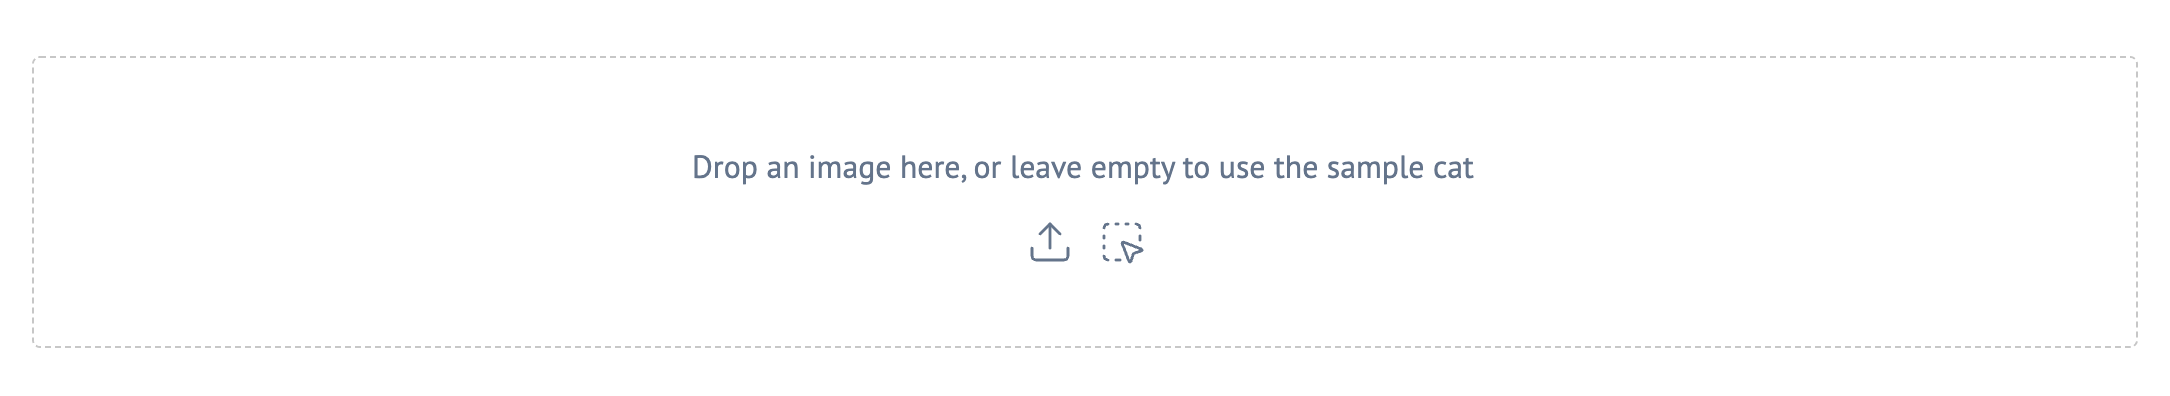

In [ ]:
# cell: image-input
image_upload = mo.ui.file(
    filetypes=["image/*"], kind="area", label="Drop an image here, or leave empty to use the sample cat"
)
image_upload

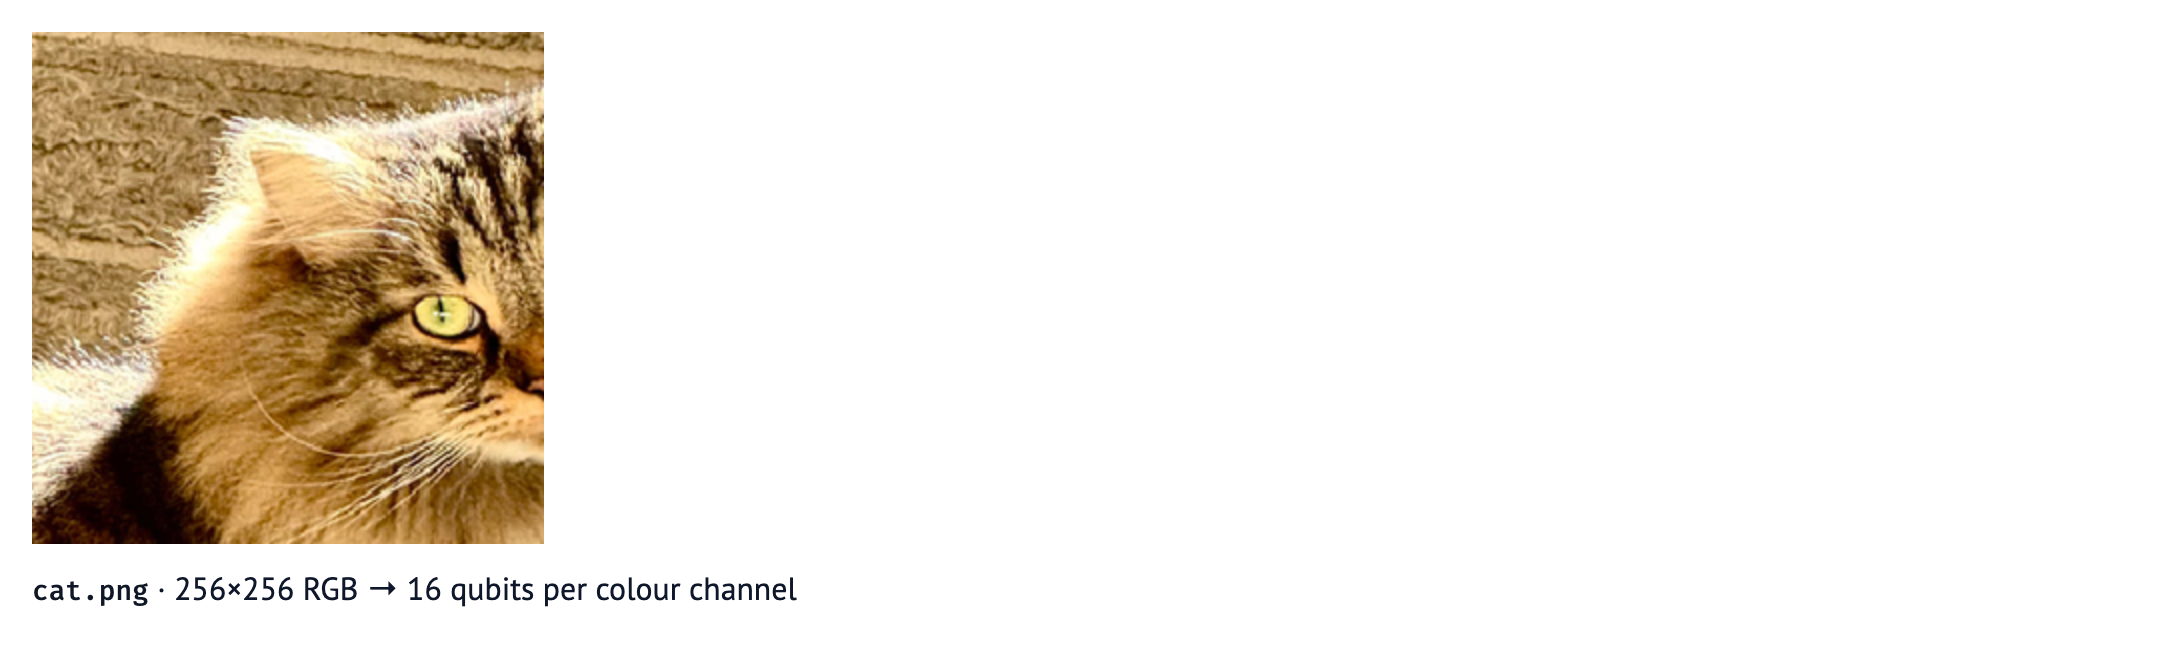

In [ ]:
# cell: image
# The uploaded image, or else the sample cat beside this notebook (fetched from GitHub if missing).
SAMPLE = mo.notebook_dir() / "cat.png"
SAMPLE_URL = "https://raw.githubusercontent.com/moth-quantum/atlas-engine-notebooks/main/blur/cat.png"

if image_upload.contents():
    image_name, image_bytes = image_upload.name(), image_upload.contents()
else:
    image_name = SAMPLE.name
    image_bytes = SAMPLE.read_bytes() if SAMPLE.exists() else requests.get(SAMPLE_URL, timeout=60).content

image = Image.open(io.BytesIO(image_bytes))
image_px = as_float(image)  # float RGB in [0, 1], what the engine's output is compared against
width, height = image.size
qubits = math.ceil(math.log2(width)) + math.ceil(math.log2(height))
mo.vstack([
    mo.image(image_bytes, width=256),
    mo.md(f"`{image_name}` · {width}×{height} {image.mode} → {qubits} qubits per colour channel"),
])

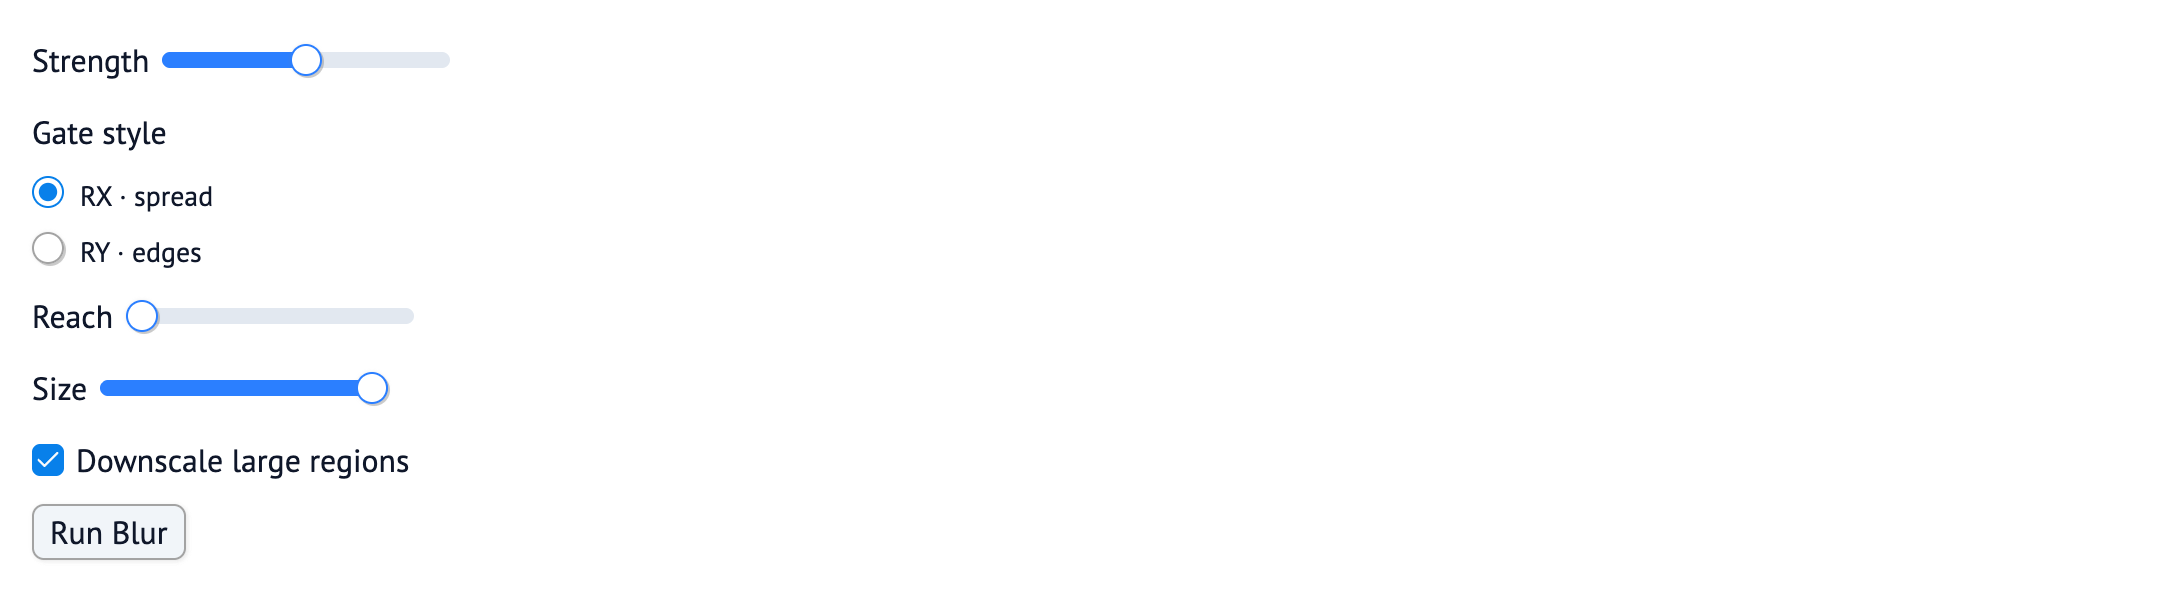

In [ ]:
# cell: params
# Keys are the engine's parameter names, so params.value is the dict sent to the API.
params = mo.ui.dictionary({
    "strength": mo.ui.slider(0, 1, step=0.05, value=0.5, label="Strength"),
    "style": mo.ui.radio(options={"RX · spread": "rx", "RY · edges": "ry"}, value="RX · spread", label="Gate style"),
    "reach": mo.ui.slider(0, 1, step=0.05, value=0.0, label="Reach"),
    "size": mo.ui.slider(8, 1024, step=8, value=1024, label="Size"),
    "downscale": mo.ui.checkbox(value=True, label="Downscale large regions"),
})
run = mo.ui.run_button(label="Run Blur")
mo.vstack([params.vstack(), run])

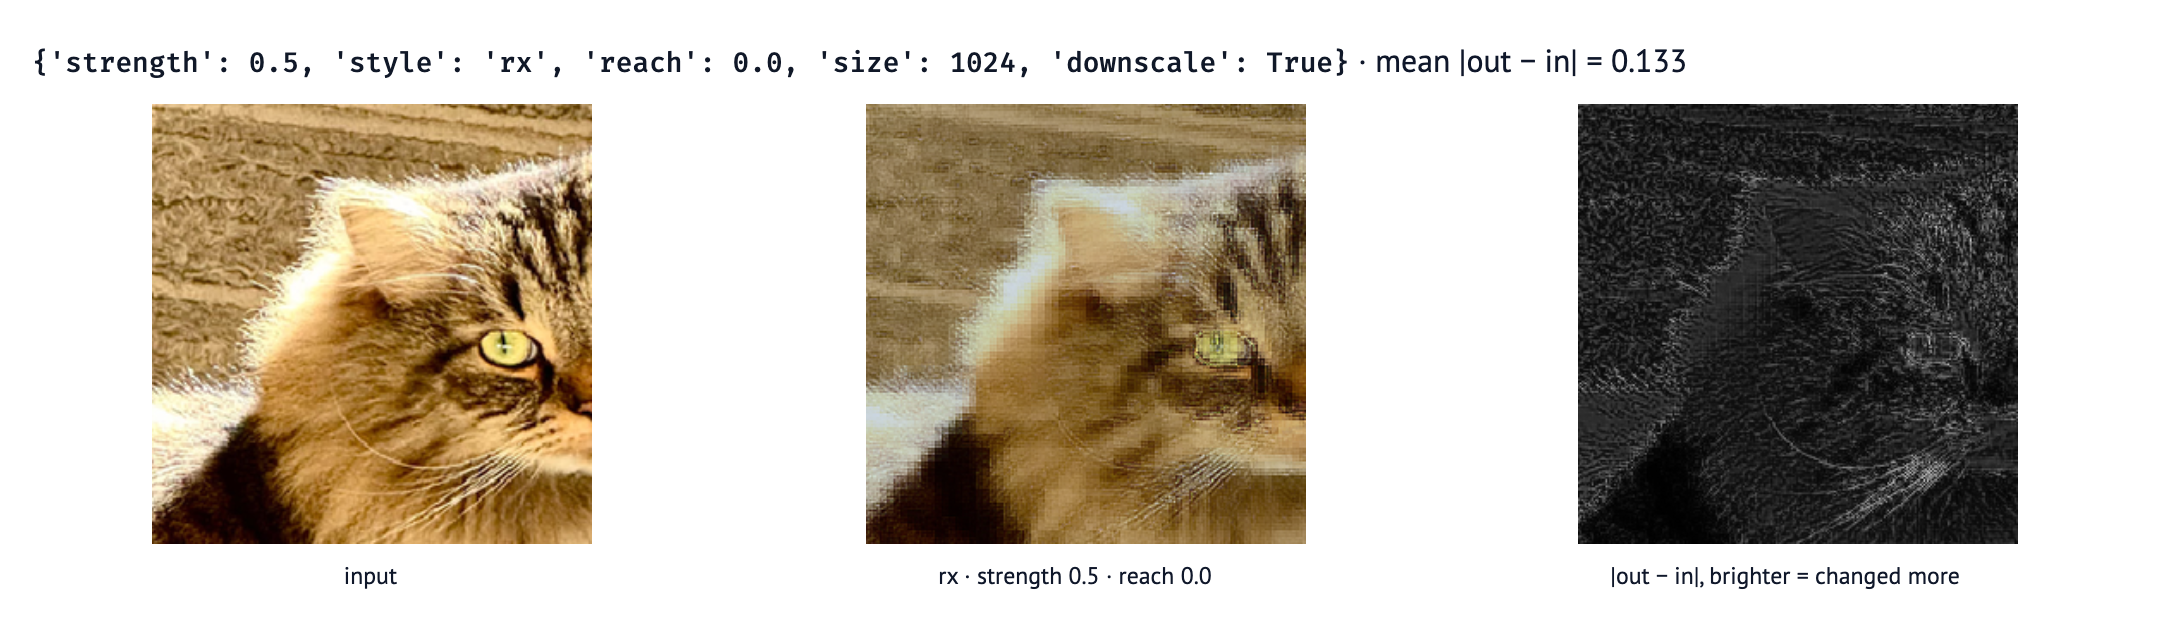

In [ ]:
# cell: run
mo.stop(not run.value, mo.md("Press **Run Blur** to blur the image with these settings."))
job_params = params.value
blurred = blur(job_params, image_bytes, image_name)
change = np.abs(blurred - image_px)
mo.vstack([
    mo.md(f"`{job_params}` · mean |out − in| = {change.mean():.3f}"),
    row({
        "input": image_px,
        f"{job_params['style']} · strength {job_params['strength']} · reach {job_params['reach']}": blurred,
        "|out − in|, brighter = changed more": change.mean(-1) / max(change.max(), 1e-6),
    }),
])

## Parameters

| name | type | default | what it does |
|---|---|---|---|
| `image` (input file) | PNG / JPEG / WebP / TIFF / BMP, any mode | required | blurred one RGB channel at a time; alpha is passed through |
| `mask` (input file) | image | none | blurs each connected region of the mask on its own and blends by mask intensity; without one, the alpha channel is used, else the whole canvas |
| `strength` | float, 0 to 1 | 0.5 | scales every rotation; 0 returns the input unchanged |
| `style` | `rx` or `ry` | `rx` | `rx` spreads echoes across the image, `ry` concentrates them on edges |
| `reach` | float, 0 to 1 | 0 | 0 weights each angle by local brightness, 1 turns every qubit equally |
| `size` | int, 8 to 1024 | 1024 | pixel budget per pass: $2\lceil\log_2 \text{size}\rceil$ qubits |
| `downscale` | bool | true | a region over budget is downscaled (true) or tiled (false), never the whole image |

**Returns:** the blurred image, in the same format and size as the input.

## How it works

Quantum Blur has no convolution kernel. The image is encoded as a single quantum state, each qubit is rotated once, and the state is measured back into pixels. Because a single gate redistributes amplitude between pixels that may be far apart on the canvas, the output shows interference patterns rather than soft focus.

**Encode.** Pixel $(x,y)$ with brightness $h$ maps to a basis state, Gray-coded per axis:

$$|\psi\rangle \;\propto\; \sum_{x,y} \sqrt{h(x,y)}\;|g(x)\,g(y)\rangle, \qquad n = \lceil\log_2 W\rceil + \lceil\log_2 H\rceil \text{ qubits}$$

**Rotate.** One `rx` (or `ry`) per qubit, with an image-dependent angle:

$$\theta_q = \pi\,\xi\,\big[(1-\text{reach})\, r_q + \text{reach}\big], \qquad \xi = \text{strength} \;(\texttt{rx})\;\text{ or }\;\text{strength}^2 \;(\texttt{ry})$$

where $r_q$ is the normalised brightness on neighbour pairs whose labels differ in qubit $q$.

**Read back.** $h' = |\text{amp}|^2 / \max$, rescaled to the channel's original maximum. With a mask $m$, the output is $m\cdot\text{blurred} + (1-m)\cdot\text{original}$.

## Experiments

Each experiment changes one parameter and keeps the others fixed. Press its button to run it.

### Strength

$\xi$ scales every angle. At 0 the round trip is exact; the echoes grow with it up to the limit of 1 (past that the rotations would start to undo themselves, which is why the engine stops there).

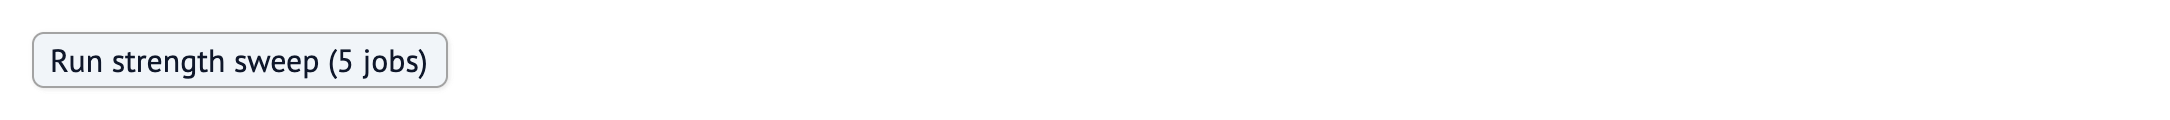

In [ ]:
# cell: strength-params
# Edit the values, then press the button: one job per value.
STRENGTH_SWEEP = (0.0, 0.25, 0.5, 0.75, 1.0)
STRENGTH_FIXED = {"style": "rx", "reach": 0.0}
run_strength = mo.ui.run_button(label=f"Run strength sweep ({len(STRENGTH_SWEEP)} jobs)")
run_strength

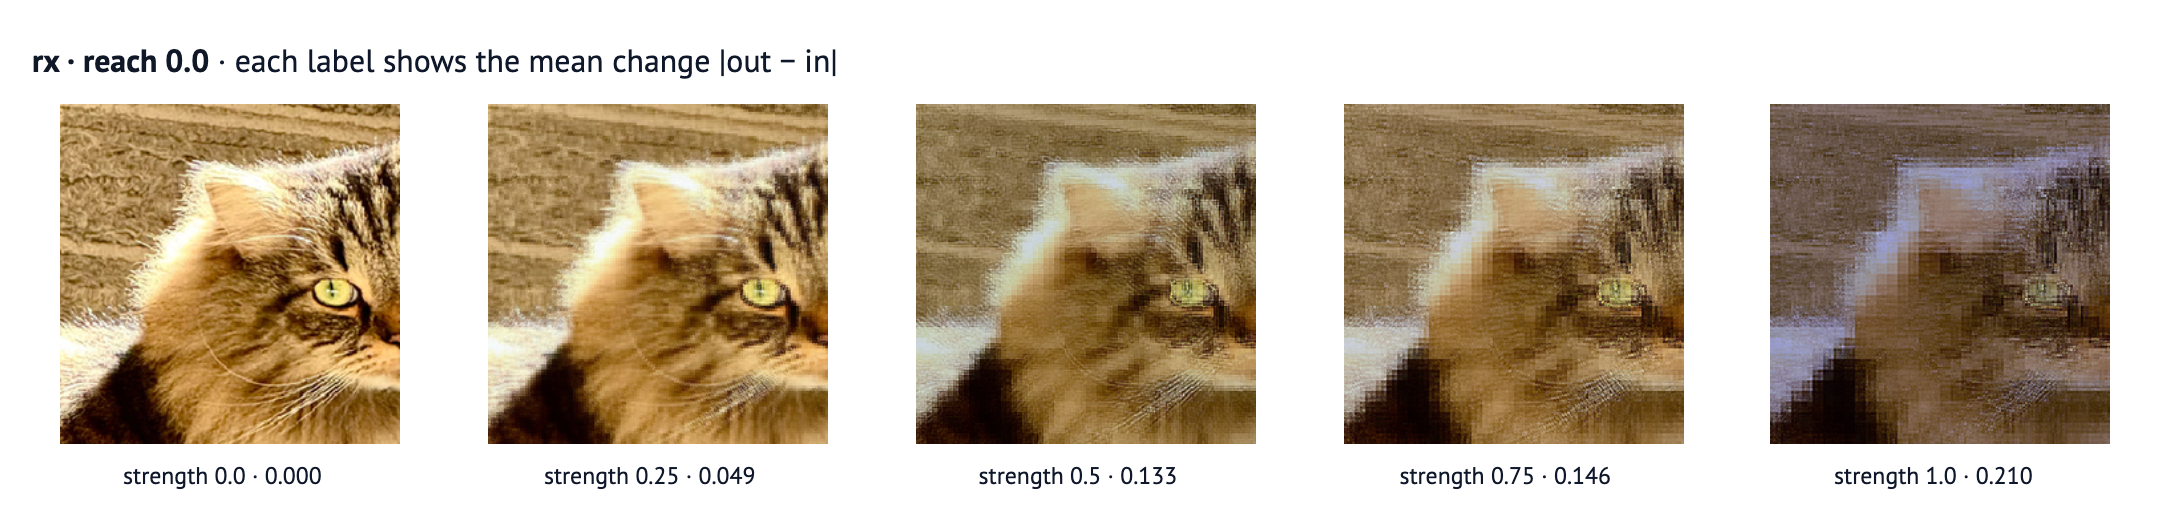

In [ ]:
# cell: strength
mo.stop(
    not run_strength.value,
    mo.md("Press **Run strength sweep** to compare the strengths above."),
)
results = {
    value: blur({**STRENGTH_FIXED, "strength": value}, image_bytes, image_name)
    for value in STRENGTH_SWEEP
}
changes = {value: np.abs(out - image_px).mean() for value, out in results.items()}
mo.vstack([
    mo.md(
        f"**{STRENGTH_FIXED['style']} · reach {STRENGTH_FIXED['reach']}** · "
        "each label shows the mean change |out − in|"
    ),
    row({f"strength {value} · {changes[value]:.3f}": out for value, out in results.items()}, width=170),
])

### Reach and style

`reach` lifts the locality: at 0 the angle on each qubit is weighted by the brightness it separates, at 1 every qubit turns by the same $\pi\xi$ and echoes land anywhere on the canvas. `ry` keeps the same angles (with $\xi = \text{strength}^2$) but its interference terms cancel instead of spreading, so weight collects at a few pixels and smooth areas go dark.

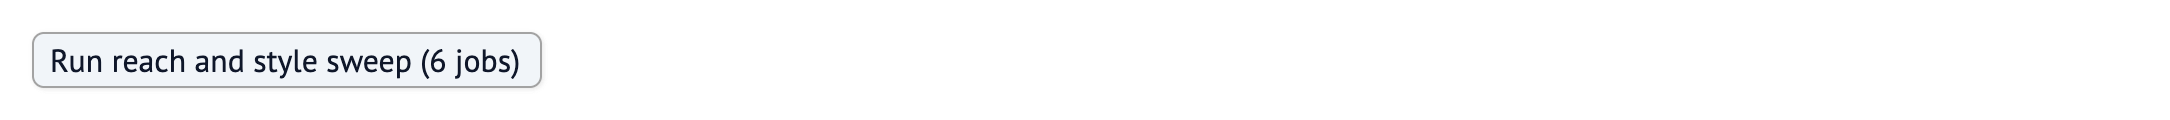

In [ ]:
# cell: reach-params
# Edit the values, then press the button: one job per style × reach.
REACH_SWEEP = (0.0, 0.5, 1.0)
REACH_STYLES = ("rx", "ry")
REACH_FIXED = {"strength": 0.5}
run_reach = mo.ui.run_button(label=f"Run reach and style sweep ({len(REACH_STYLES) * len(REACH_SWEEP)} jobs)")
run_reach

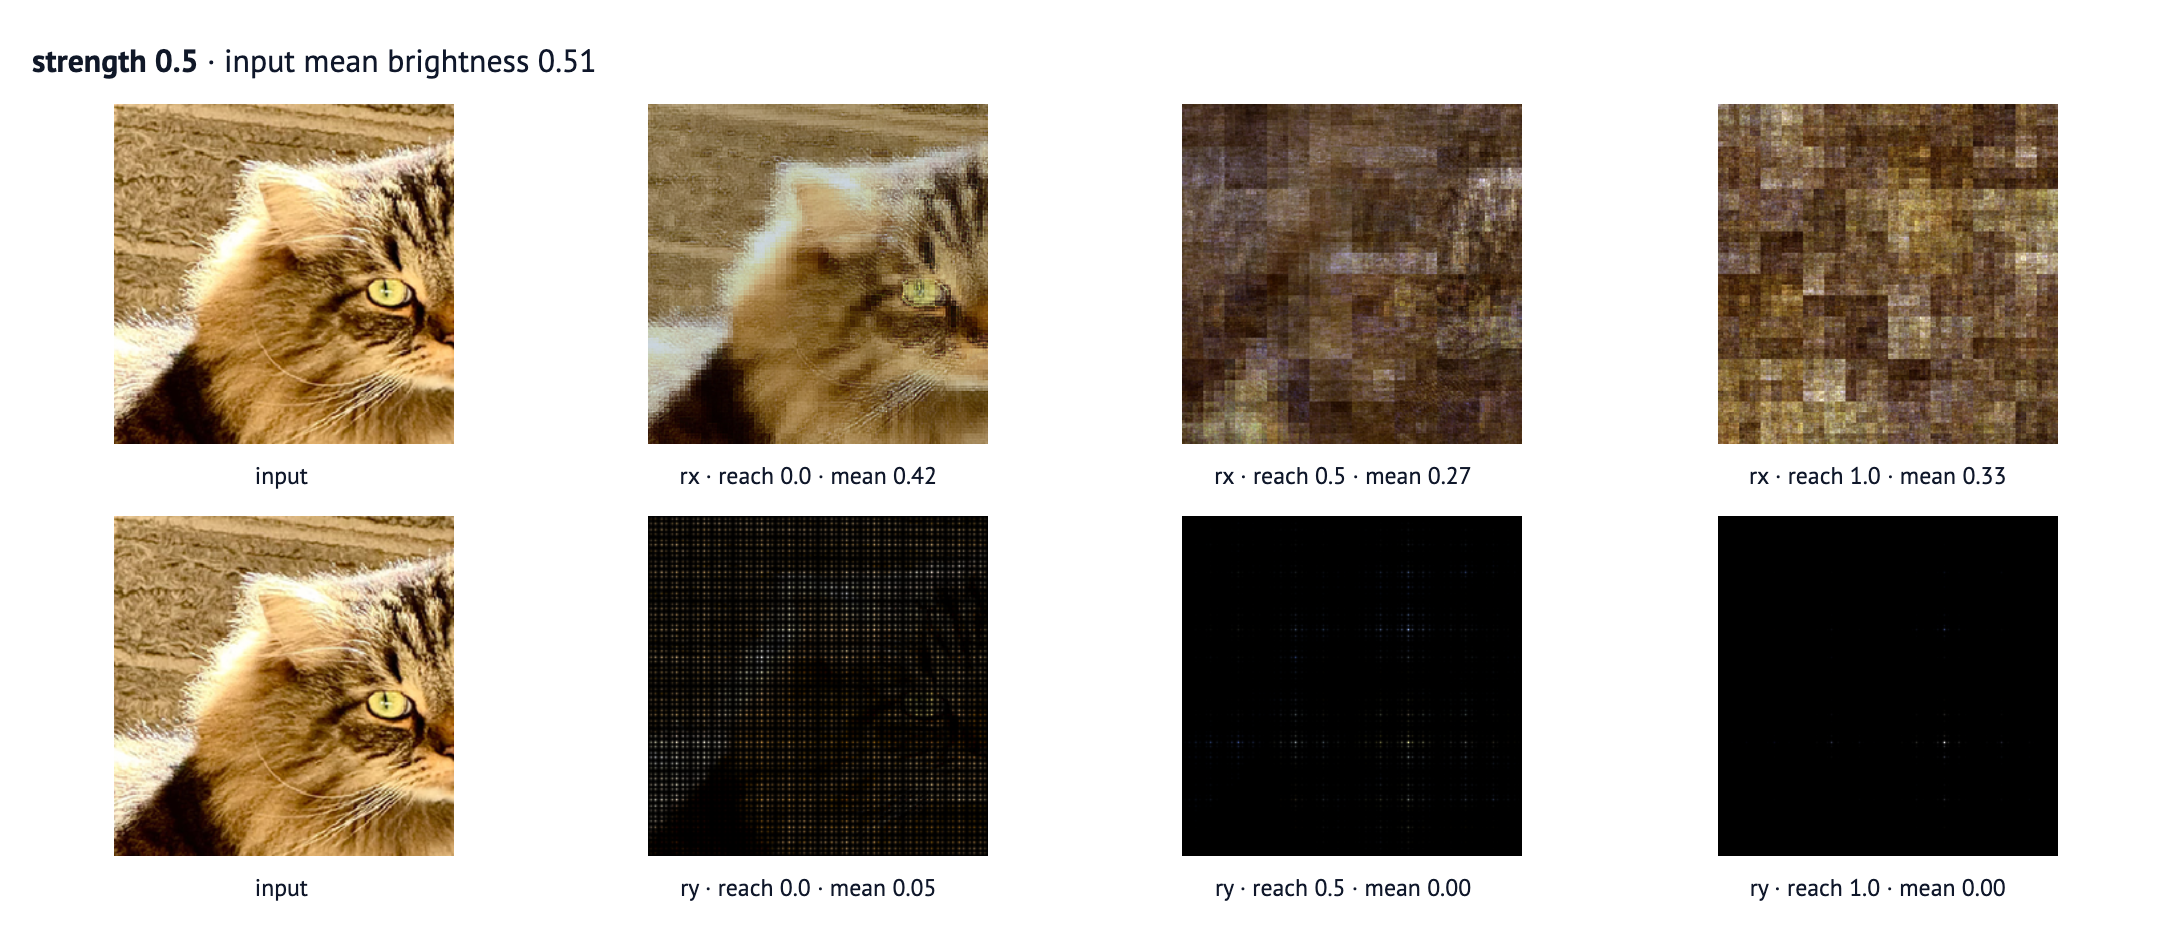

In [ ]:
# cell: reach
mo.stop(
    not run_reach.value,
    mo.md("Press **Run reach and style sweep** to compare both gate styles across reach."),
)
rows = []
for gate in REACH_STYLES:
    panels = {"input": image_px}
    for amount in REACH_SWEEP:
        out = blur({**REACH_FIXED, "style": gate, "reach": amount}, image_bytes, image_name)
        panels[f"{gate} · reach {amount} · mean {out.mean():.2f}"] = out
    rows.append(row(panels, width=170))
mo.vstack([
    mo.md(f"**strength {REACH_FIXED['strength']}** · input mean brightness {image_px.mean():.2f}"),
    *rows,
])

### Mask

A feathered disc: 1 inside, a soft ramp, 0 outside. The engine blurs the disc's bounding box as its own state and blends by mask intensity, so pixels outside the mask must come back untouched and the edge must be a gradient, not a seam.

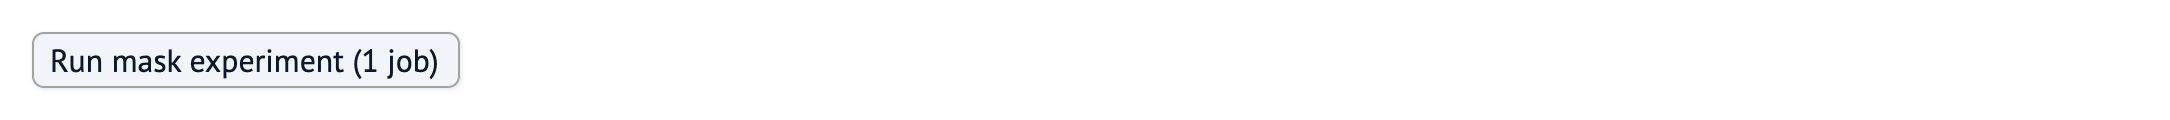

In [ ]:
# cell: mask-params
# Edit these, then press the button (one job).
MASK_PARAMS = {"style": "rx", "reach": 0.0, "strength": 0.8}
MASK_RADIUS = 0.28  # disc scale, as a fraction of the image's shorter side
MASK_RAMP = 1.6  # mask = clip(MASK_RAMP - distance / radius, 0, 1): 1 inside, a soft edge, 0 outside
run_mask = mo.ui.run_button(label="Run mask experiment (1 job)")
run_mask

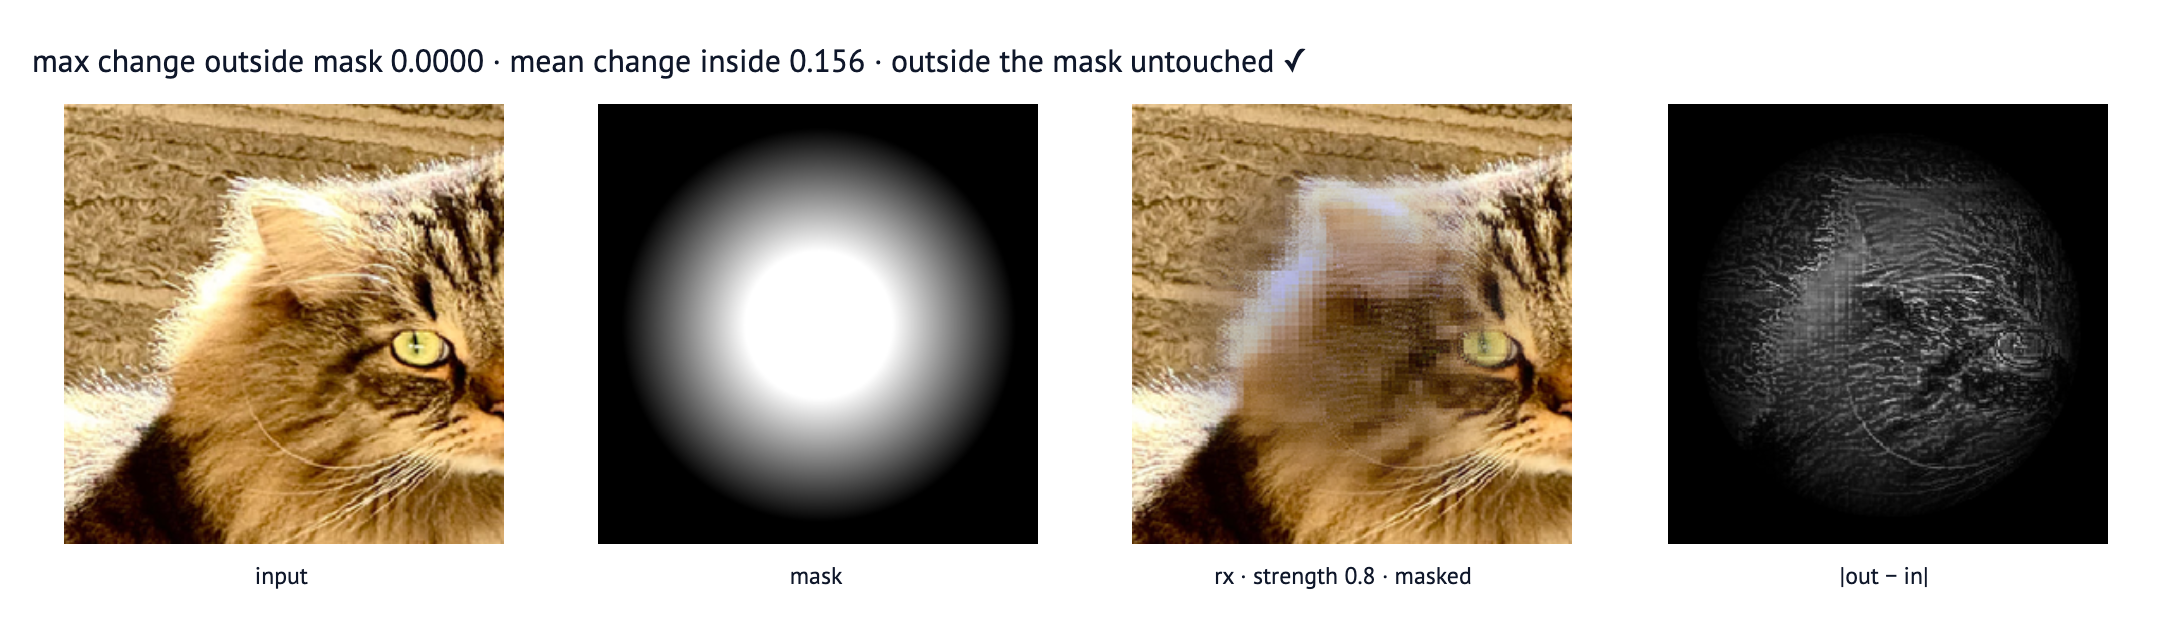

In [ ]:
# cell: mask
mo.stop(
    not run_mask.value,
    mo.md("Press **Run mask experiment** to blur only inside the disc."),
)
yy, xx = np.mgrid[0:height, 0:width]
distance = np.hypot(xx - width / 2, yy - height / 2) / (MASK_RADIUS * min(width, height))
mask = np.clip(MASK_RAMP - distance, 0, 1)  # 1 inside the disc, a soft ramp, 0 outside
masked = blur(MASK_PARAMS, image_bytes, image_name, mask=png(mask))
mask_change = np.abs(masked - image_px).mean(-1)
max_outside = mask_change[mask == 0].max()
mean_inside = mask_change[mask == 1].mean()
verdict = "outside the mask untouched ✓" if max_outside < 1 / 255 else "**pixels outside the mask changed**"
mo.vstack([
    mo.md(f"max change outside mask {max_outside:.4f} · mean change inside {mean_inside:.3f} · {verdict}"),
    row({
        "input": image_px,
        "mask": mask,
        f"{MASK_PARAMS['style']} · strength {MASK_PARAMS['strength']} · masked": masked,
        "|out − in|": mask_change / max(mask_change.max(), 1e-6),
    }),
])

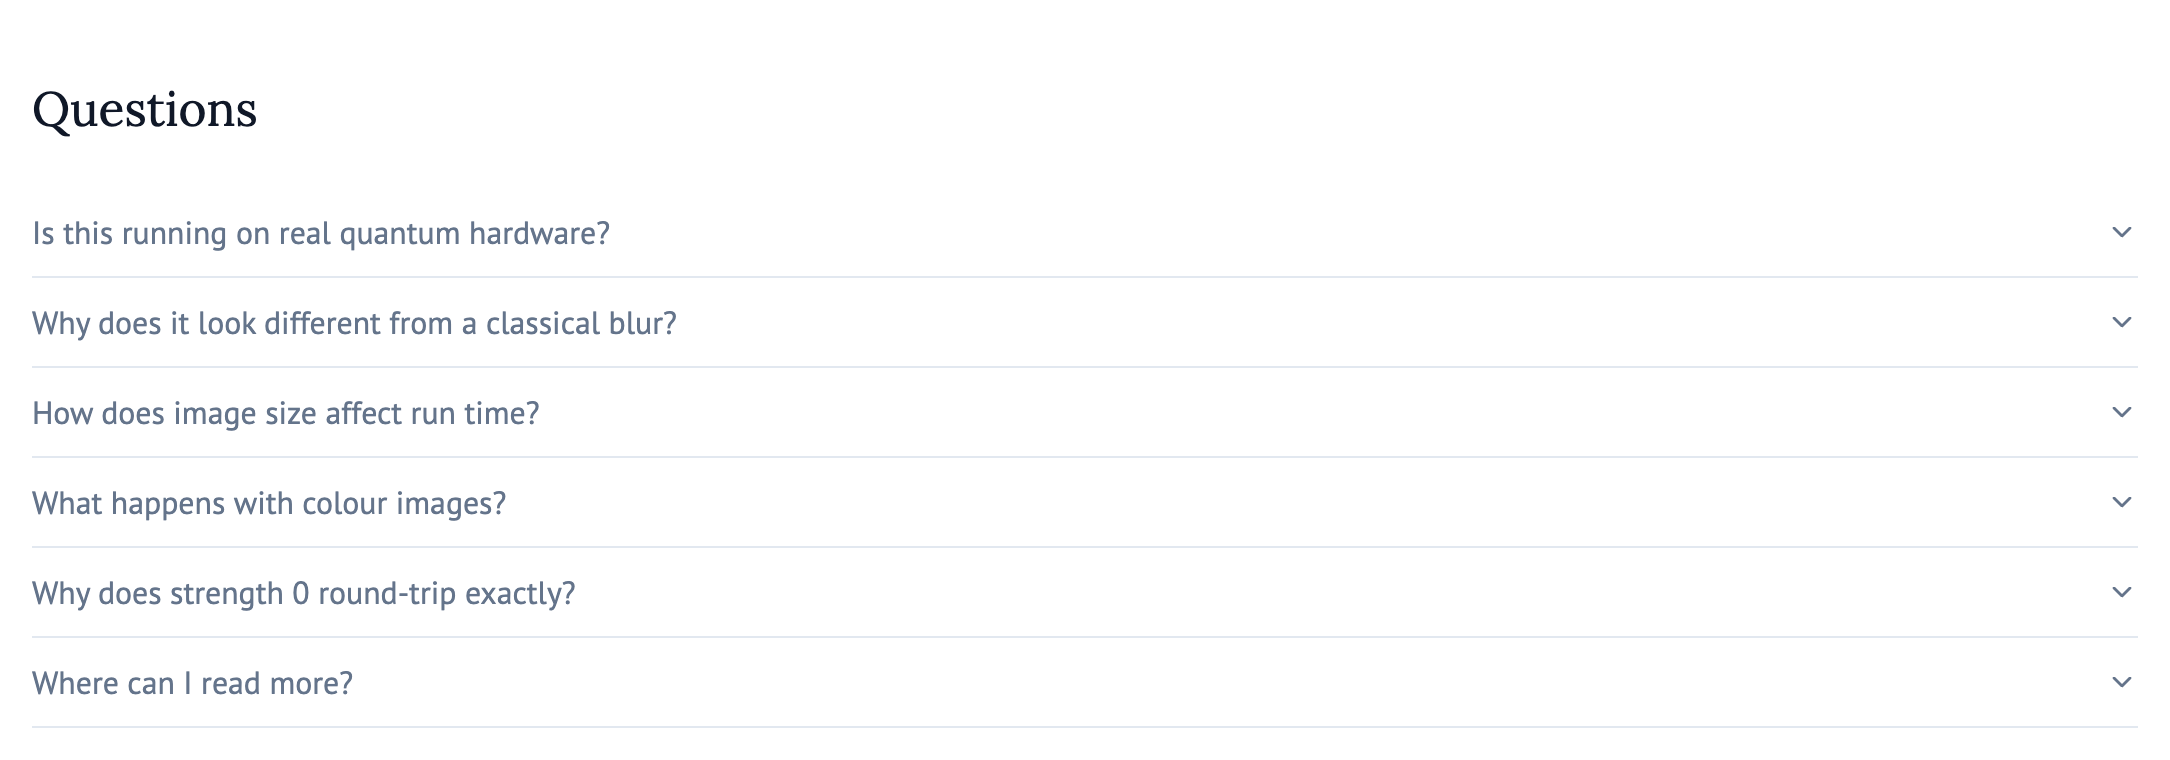

In [ ]:
# cell: questions
mo.vstack([mo.md("## Questions"), mo.accordion({
    "Is this running on real quantum hardware?":
        "No. Blur runs on a classical statevector simulator, so jobs run on CPU or GPU. The circuits and the interference are real; the execution is emulated. That keeps results exact and repeatable with no shot noise. Real hardware would need very high connectivity and enough shots to rebuild the whole state, which is not yet practical at image scale.",
    "Why does it look different from a classical blur?":
        "A classical blur averages each pixel with a fixed neighbourhood. Blur has no kernel: one rotation per qubit mixes amplitude between every pixel at once, so the shape of the smear comes from the circuit, not a window. That is where the echo-like, non-local look comes from.",
    "How does image size affect run time?":
        "Qubits grow with the log of the image size (16 for 256 × 256, 20 for 1024 × 1024), but simulator memory and time grow exponentially with qubits. Regions over the qubit budget are downscaled or tiled, depending on `downscale`.",
    "What happens with colour images?":
        "Each of red, green and blue is blurred as its own state and the channels are recombined. The same technique was used on ILĀ's [Recurse album](https://infinite.mothquantum.com).",
    "Why does strength 0 round-trip exactly?":
        "Encoding normalises the state, which throws away absolute brightness. The engine keeps each channel's original maximum and restores it on read-back, so with no rotation the output equals the input.",
    "Where can I read more?":
        "The open-source [QuantumBlur repository](https://github.com/qiskit-community/QuantumBlur) walks through the underlying library.",
})])